# EDA with SQL

In [7]:
%load_ext sql

In [11]:
import csv, sqlite3
import prettytable
prettytable.DEFAULT = 'DEFAULT'

con = sqlite3.connect('my_data1.db')
cur = con.cursor()

%sql sqlite:///my_data1.db

In [12]:
import pandas as pd
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/labs/module_2/data/Spacex.csv"
df = pd.read_csv(url)
df.to_sql('SPACEXTBL', con, if_exists='replace',index=False,method='multi')

101

In [13]:
#DROP THE TABLE IF EXISTS

%sql DROP TABLE IF EXISTS SPACEXTABLE;

 * sqlite:///my_data1.db
Done.


[]

In [14]:
%sql create table SPACEXTABLE as select * from SPACEXTBL where Date is not null

 * sqlite:///my_data1.db
Done.


[]

In [32]:
df['Landing_Outcome'].value_counts()

Landing_Outcome
Success                   38
No attempt                21
Success (drone ship)      14
Success (ground pad)       9
Controlled (ocean)         5
Failure (drone ship)       5
Failure                    3
Failure (parachute)        2
Uncontrolled (ocean)       2
Precluded (drone ship)     1
No attempt                 1
Name: count, dtype: int64

## Task 1
**Display the names of the unique launch sites in the space mission**

In [17]:
query1 = """
        SELECT DISTINCT
            Launch_Site
        FROM SPACEXTBL;
        """
result1 = %sql $query1
print(result1)

 * sqlite:///my_data1.db
Done.
+--------------+
| Launch_Site  |
+--------------+
| CCAFS LC-40  |
| VAFB SLC-4E  |
|  KSC LC-39A  |
| CCAFS SLC-40 |
+--------------+


## Task 2
**Display 5 records where launch sites begin with the string 'CCA'**

In [26]:
query2 = """
        SELECT * FROM SPACEXTBL
        WHERE Launch_Site LIKE 'CCA%'
        LIMIT 5;
        """
result2 = %sql $query2
result2.DataFrame()

 * sqlite:///my_data1.db
Done.


,Date,Time (UTC),Booster_Version,Launch_Site,Payload,PAYLOAD_MASS__KG_,Orbit,Customer,Mission_Outcome,Landing_Outcome
0,2010-06-04,18:45:00,F9 v1.0 B0003,CCAFS LC-40,Dragon Spacecraft Qualification Unit,0,LEO,SpaceX,Success,Failure (parachute)
1,2010-12-08,15:43:00,F9 v1.0 B0004,CCAFS LC-40,"Dragon demo flight C1, two CubeSats, barrel of...",0,LEO (ISS),NASA (COTS) NRO,Success,Failure (parachute)
2,2012-05-22,7:44:00,F9 v1.0 B0005,CCAFS LC-40,Dragon demo flight C2,525,LEO (ISS),NASA (COTS),Success,No attempt
3,2012-10-08,0:35:00,F9 v1.0 B0006,CCAFS LC-40,SpaceX CRS-1,500,LEO (ISS),NASA (CRS),Success,No attempt
4,2013-03-01,15:10:00,F9 v1.0 B0007,CCAFS LC-40,SpaceX CRS-2,677,LEO (ISS),NASA (CRS),Success,No attempt


## Task 3
**Display the total payload mass carried by boosters launched by NASA (CRS)**

In [27]:
query3 = """
        SELECT 
            SUM(PAYLOAD_MASS__KG_) AS TOTAL_PAYLOAD_MASS_KG
        FROM SPACEXTBL
        WHERE
            Customer = 'NASA (CRS)';
        """
result3 = %sql $query3
print(result3)

 * sqlite:///my_data1.db
Done.
+-----------------------+
| TOTAL_PAYLOAD_MASS_KG |
+-----------------------+
|         45596         |
+-----------------------+


## Task 4
**Display average payload mass carried by booster version F9 v1.1**

In [28]:
query4 = """
        SELECT
            AVG(PAYLOAD_MASS__KG_) AS AVG_PAYLOAD_MASS_KG
        FROM SPACEXTBL
        WHERE
            Booster_Version = 'F9 v1.1';
        """
result4 = %sql $query4
print(result4)

 * sqlite:///my_data1.db
Done.
+---------------------+
| AVG_PAYLOAD_MASS_KG |
+---------------------+
|        2928.4       |
+---------------------+


## Task 5

##### List the date when the first succesful landing outcome in ground pad was acheived.

In [33]:
query5 = """
        SELECT 
            MIN(DATE) AS DATE
        FROM SPACEXTBL
        WHERE
            Landing_Outcome = 'Success (ground pad)'
        ;
        """
result5 = %sql $query5
print(result5)

 * sqlite:///my_data1.db
Done.
+------------+
|    DATE    |
+------------+
| 2015-12-22 |
+------------+


## Task 6

##### List the names of the boosters which have success in drone ship and have payload mass greater than 4000 but less than 6000

In [36]:
query6 = """
        SELECT
            Booster_Version
        FROM SPACEXTBL
        WHERE
            PAYLOAD_MASS__KG_ > 4000
        AND
            PAYLOAD_MASS__KG_ < 6000
        AND
            Landing_Outcome = 'Success (drone ship)'
        ;
        """
result6 = %sql $query6
result6.DataFrame()

 * sqlite:///my_data1.db
Done.


,Booster_Version
0,F9 FT B1022
1,F9 FT B1026
2,F9 FT B1021.2
3,F9 FT B1031.2


## Task 7


##### List the total number of successful and failure mission outcomes

In [56]:
query7 = """
        SELECT
            COUNT(Date) AS NUMBER_MISSION_OUTCOMES,
            CASE 
                WHEN Landing_Outcome LIKE '%Success%' THEN 'Success'
                WHEN Landing_Outcome LIKE '%Failure%' THEN 'Failure'
            END AS Landing_Outcome_Grouped
        FROM SPACEXTBL
        WHERE
            Landing_Outcome LIKE '%Failure%'
        OR
            Landing_Outcome LIKE '%Success%'
        GROUP BY
            Landing_Outcome_Grouped
        ;
        """
result7 = %sql $query7
print(result7)

 * sqlite:///my_data1.db
Done.
+-------------------------+-------------------------+
| NUMBER_MISSION_OUTCOMES | Landing_Outcome_Grouped |
+-------------------------+-------------------------+
|            10           |         Failure         |
|            61           |         Success         |
+-------------------------+-------------------------+


## Task 8

##### List all the booster_versions that have carried the maximum payload mass, using a subquery with a suitable aggregate function.

In [46]:
query8 = """ 
        SELECT DISTINCT
            Booster_Version
        FROM SPACEXTBL
        WHERE
            PAYLOAD_MASS__KG_ = (SELECT MAX(PAYLOAD_MASS__KG_) FROM SPACEXTBL)
        ;
        """
result8 = %sql $query8
print(result8)
            

 * sqlite:///my_data1.db
Done.
+-----------------+
| Booster_Version |
+-----------------+
|  F9 B5 B1048.4  |
|  F9 B5 B1049.4  |
|  F9 B5 B1051.3  |
|  F9 B5 B1056.4  |
|  F9 B5 B1048.5  |
|  F9 B5 B1051.4  |
|  F9 B5 B1049.5  |
|  F9 B5 B1060.2  |
|  F9 B5 B1058.3  |
|  F9 B5 B1051.6  |
|  F9 B5 B1060.3  |
|  F9 B5 B1049.7  |
+-----------------+


## Task 9


##### List the records which will display the month names, failure landing_outcomes in drone ship ,booster versions, launch_site for the months in year 2015.

**Note: SQLLite does not support monthnames. So you need to use  substr(Date, 6,2) as month to get the months and substr(Date,0,5)='2015' for year.**

In [50]:
query9 = """
        SELECT
            SUBSTR(DATE,6,2) AS MONTH,
            SUBSTR(DATE,0,5) AS YEAR,
            Booster_Version,
            Landing_Outcome,
            Launch_Site
        FROM SPACEXTBL
        WHERE
            Landing_Outcome = 'Failure (drone ship)'
        AND
            SUBSTR(DATE,0,5) = '2015'
        ;
        """
result9 = %sql $query9
print(result9)

 * sqlite:///my_data1.db
Done.
+-------+------+-----------------+----------------------+-------------+
| MONTH | YEAR | Booster_Version |   Landing_Outcome    | Launch_Site |
+-------+------+-----------------+----------------------+-------------+
|   01  | 2015 |  F9 v1.1 B1012  | Failure (drone ship) | CCAFS LC-40 |
|   04  | 2015 |  F9 v1.1 B1015  | Failure (drone ship) | CCAFS LC-40 |
+-------+------+-----------------+----------------------+-------------+


## Task 10




##### Rank the count of landing outcomes (such as Failure (drone ship) or Success (ground pad)) between the date 2010-06-04 and 2017-03-20, in descending order.

In [55]:
query10 = """
        SELECT
            COUNT(Date) as Count,
            Landing_Outcome
        FROM SPACEXTBL
        WHERE
            DATE BETWEEN '2010-06-04' AND '2017-03-20'
        GROUP BY
            Landing_Outcome
        ORDER BY
            Count DESC
        ;
        """
result10 = %sql $query10
print(result10)

 * sqlite:///my_data1.db
Done.
+-------+------------------------+
| Count |    Landing_Outcome     |
+-------+------------------------+
|   10  |       No attempt       |
|   5   |  Success (drone ship)  |
|   5   |  Failure (drone ship)  |
|   3   |  Success (ground pad)  |
|   3   |   Controlled (ocean)   |
|   2   |  Uncontrolled (ocean)  |
|   2   |  Failure (parachute)   |
|   1   | Precluded (drone ship) |
+-------+------------------------+


# EDA with Visualization

In [58]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [60]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv"
df = pd.read_csv(url)
df.head(5)

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


First, let's try to see how the `FlightNumber` (indicating the continuous launch attempts.) and `Payload` variables would affect the launch outcome.

We can plot out the <code>FlightNumber</code> vs. <code>PayloadMass</code>and overlay the outcome of the launch. We see that as the flight number increases, the first stage is more likely to land successfully. The payload mass also appears to be a factor; even with more massive payloads, the first stage often returns successfully.

Text(31.45148758680554, 0.5, 'Pay load Mass (kg)')

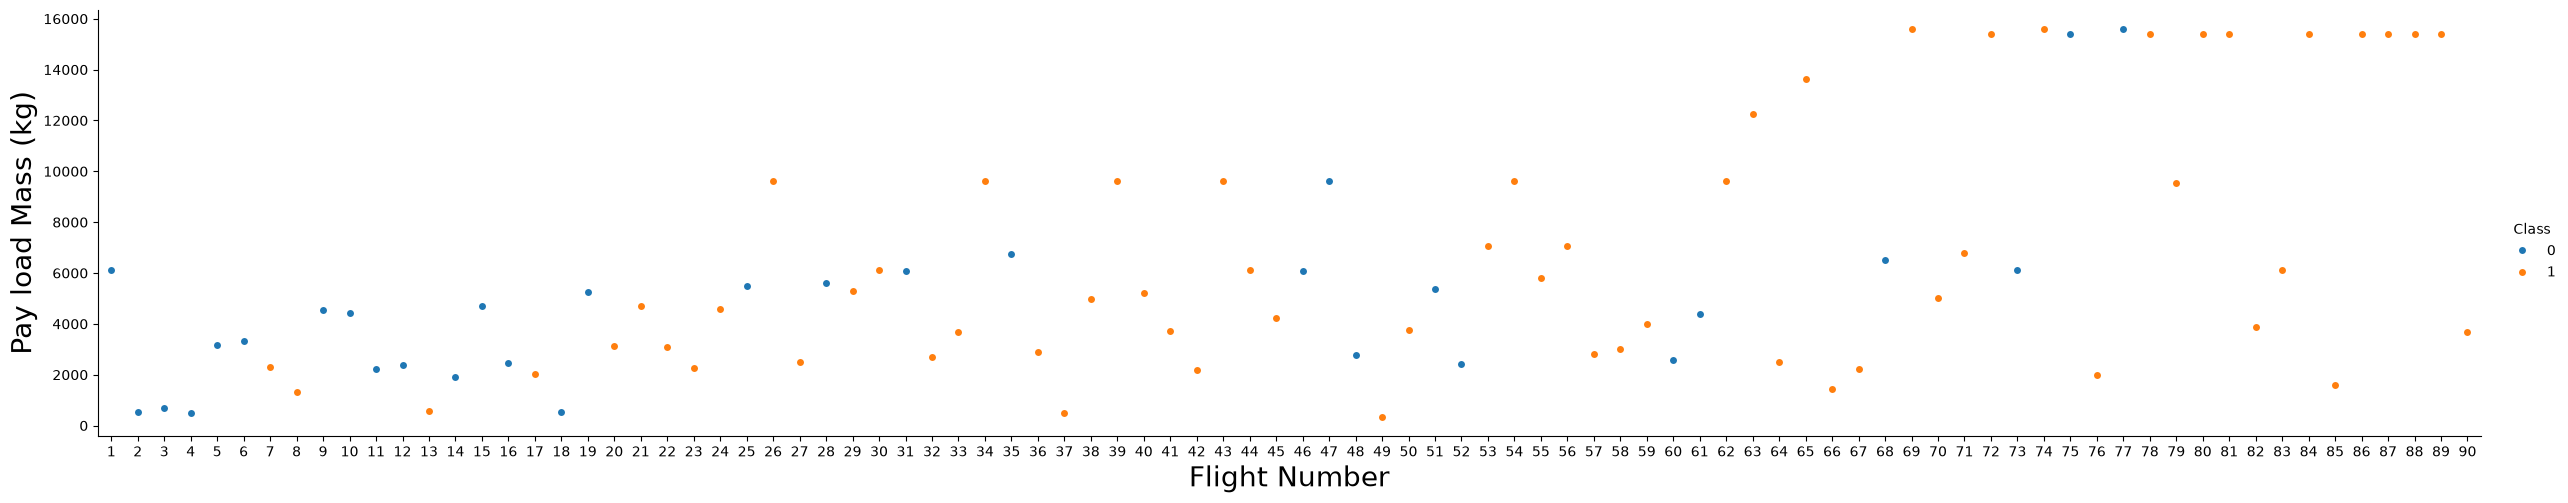

In [62]:
sns.catplot(y="PayloadMass", x="FlightNumber", hue="Class", data=df, aspect = 5)
plt.xlabel("Flight Number",fontsize=20)
plt.ylabel("Pay load Mass (kg)",fontsize=20)

## Task 1: Visualize the relationship between Flight Number and Launch Site
Use the function <code>catplot</code> to plot <code>FlightNumber</code> vs <code>LaunchSite</code>, set the  parameter <code>x</code>  parameter to <code>FlightNumber</code>,set the  <code>y</code> to <code>Launch Site</code> and set the parameter <code>hue</code> to <code>'class'</code>

Text(0.5, 1.0, 'Flight Number vs Launch Site by Class')

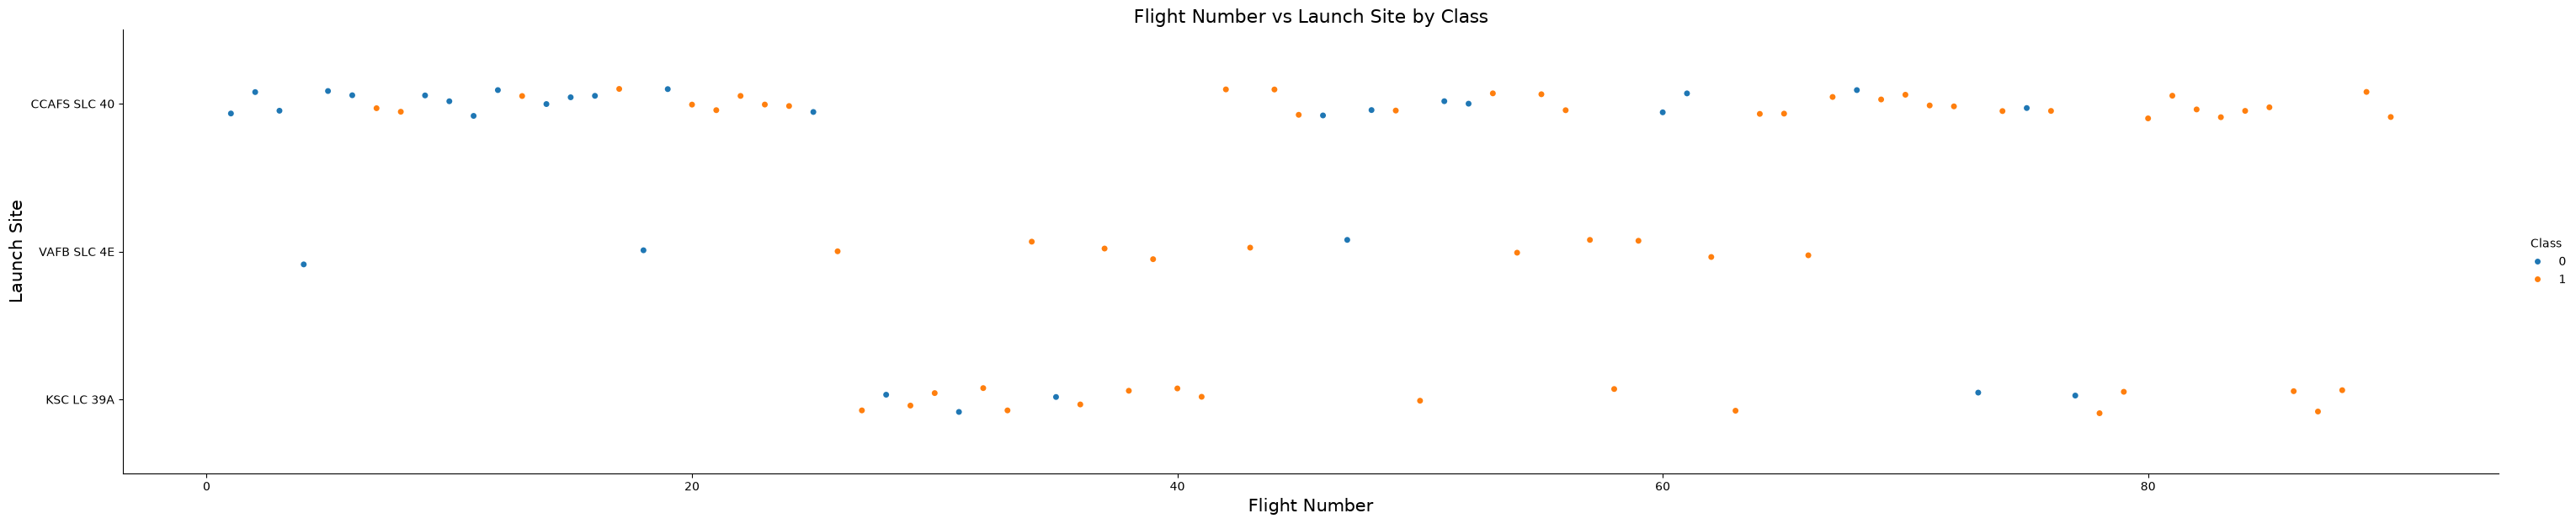

In [68]:
sns.catplot(x='FlightNumber',y='LaunchSite',data=df,hue='Class', aspect = 5, height = 6)
plt.xlabel("Flight Number", fontsize=15)
plt.ylabel("Launch Site", fontsize=15)
plt.title("Flight Number vs Launch Site by Class", fontsize=16)

We see that as the flight number increases, the first stage is more likely to land successfully. Also, with the Launch Site, the same relation

## TASK 2: Visualize the relationship between Payload Mass and Launch Site
We also want to observe if there is any relationship between launch sites and their payload mass.


Text(0.5, 1.0, 'Launch Site vs Pay load Mass')

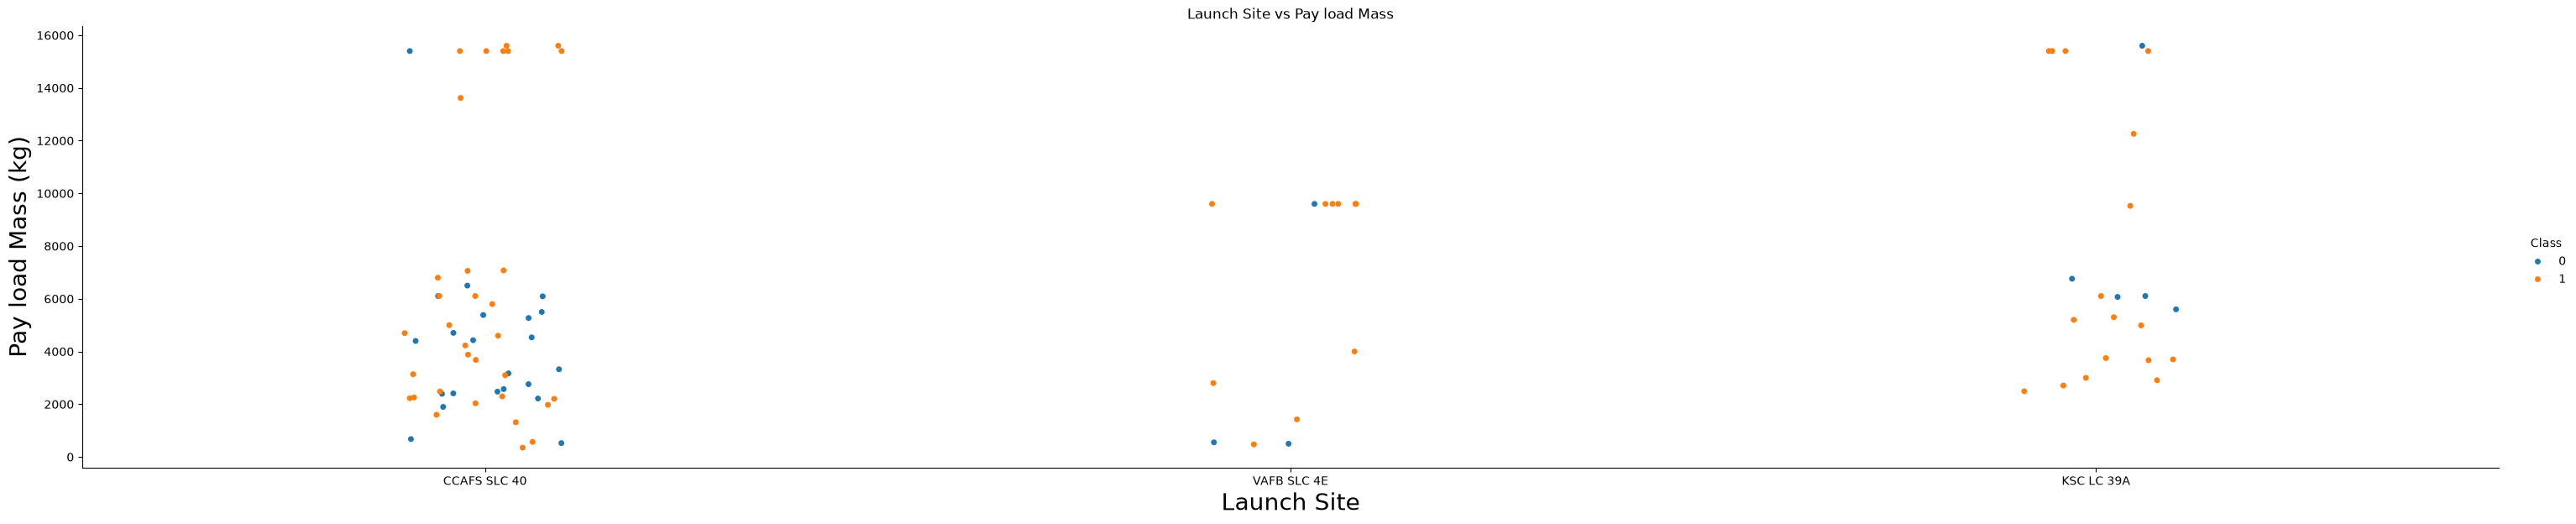

In [70]:
sns.catplot(x='LaunchSite',y='PayloadMass', data=df, hue='Class', aspect=5,height=6)
plt.xlabel('Launch Site', fontsize = 20)
plt.ylabel('Pay load Mass (kg)', fontsize =20)
plt.title('Launch Site vs Pay load Mass')

For the VAFB-SLC  launchsite there are no  rockets  launched for  heavypayload mass(greater than 10000).

### TASK  3: Visualize the relationship between success rate of each orbit type
Next, we want to visually check if there are any relationship between success rate and orbit type.
Let's create a `bar chart` for the sucess rate of each orbit

Text(0.5, 1.0, 'Success rate by Orbit type')

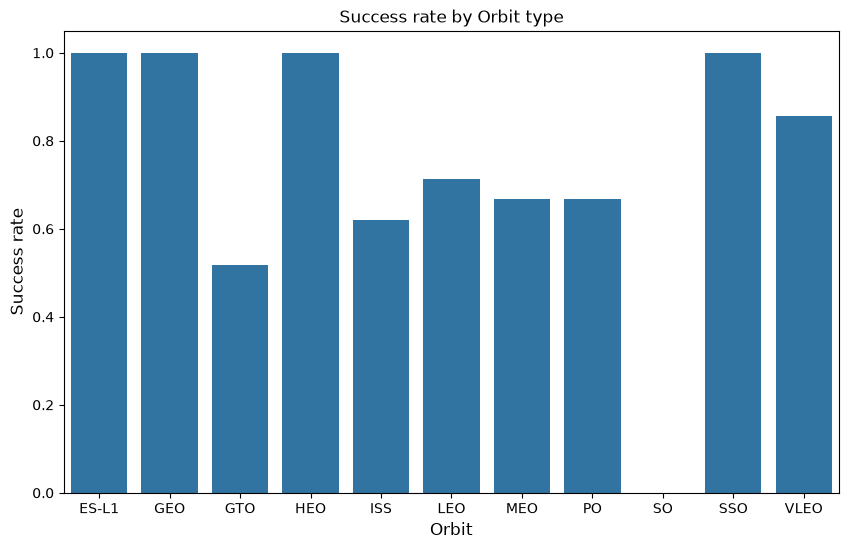

In [72]:
df_orbit = df.groupby('Orbit')['Class'].mean().reset_index()

plt.figure(figsize = (10,6))
sns.barplot(x='Orbit',y='Class',data=df_orbit)
plt.xlabel('Orbit', fontsize=12)
plt.ylabel('Success rate',fontsize=12)
plt.title('Success rate by Orbit type')

According to this figure, the orbit types `ES-L1`, `GEO`, `HEO`, `SSO` have around 100% success rate, while `GTO` has the minimum (around 50%)

## TASK  4: Visualize the relationship between FlightNumber and Orbit type
For each orbit, we want to see if there is any relationship between FlightNumber and Orbit type.


Text(0.5, 1.0, 'Flight Number vs Orbit Type')

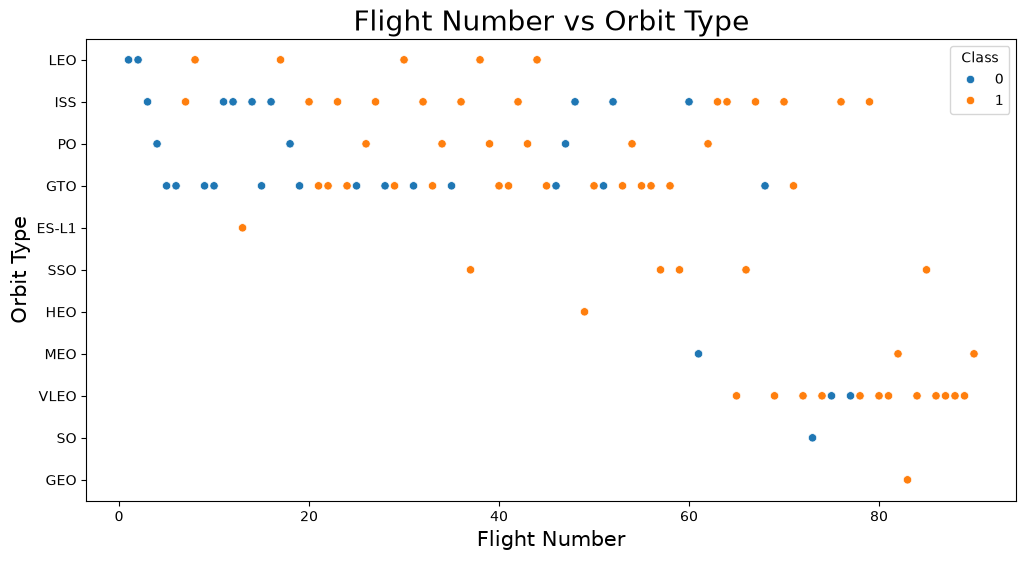

In [76]:
plt.figure(figsize=(12,6))
sns.scatterplot(x='FlightNumber',y='Orbit',data=df,hue='Class')
plt.xlabel('Flight Number', fontsize=15)
plt.ylabel('Orbit Type',fontsize=15)
plt.title('Flight Number vs Orbit Type',fontsize=20)

In the `LEO` orbit, success seems to be related to the number of flights, conversely to the other orbits.

## TASK  5: Visualize the relationship between Payload Mass and Orbit type
Similarly, we can plot the Payload Mass vs. Orbit scatter point charts to reveal the relationship between Payload Mass and Orbit type

Text(0.5, 1.0, 'Payload Mass vs Orbit Type')

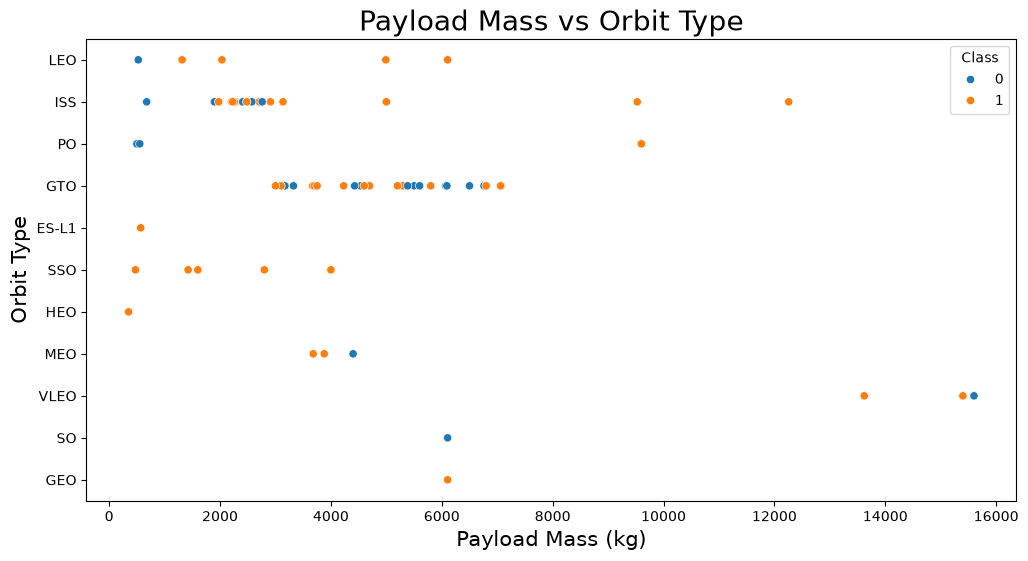

In [79]:
plt.figure(figsize=(12,6))
sns.scatterplot(x='PayloadMass',y='Orbit',data=df,hue='Class')
plt.xlabel('Payload Mass (kg)', fontsize=15)
plt.ylabel('Orbit Type',fontsize=15)
plt.title('Payload Mass vs Orbit Type',fontsize=20)

With higher payloads, the success rate for `LEO` and `ISS` seems to be higher. However, for `GTO` it's difficult to distinguish between success or not

## TASK  6: Visualize the launch success yearly trend
You can plot a line chart with x axis to be <code>Year</code> and y axis to be average success rate, to get the average launch success trend.


In [81]:
# A function to Extract years from the date 
year=[]
def Extract_year():
    for i in df["Date"]:
        year.append(i.split("-")[0])
    return year
Extract_year()
df['Date'] = year
df.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


Text(0.5, 1.0, 'Success Rate by Year')

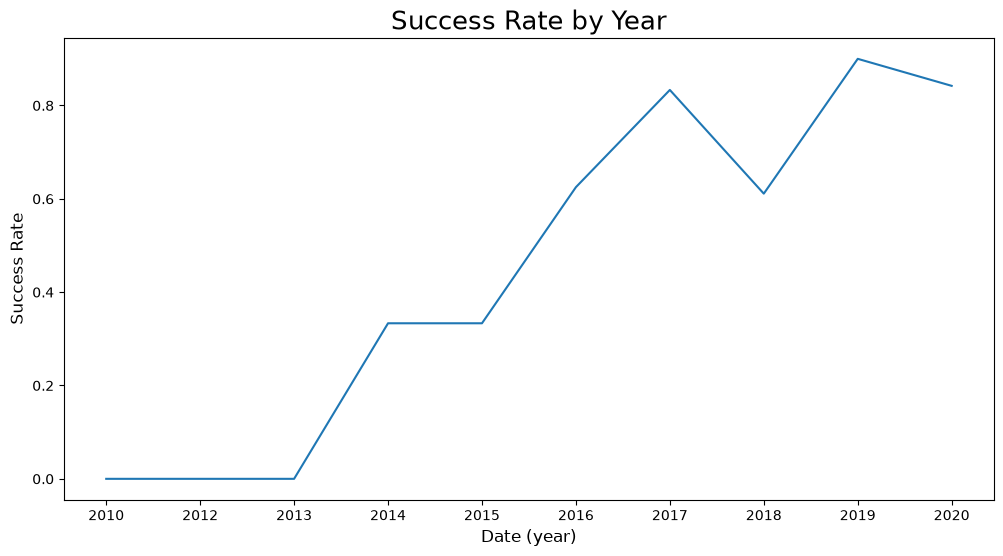

In [86]:
df_year = df.groupby('Date')['Class'].mean().reset_index()

plt.figure(figsize=(12,6))
sns.lineplot(x='Date',y='Class',data=df_year)
plt.xlabel('Date (year)',fontsize=12)
plt.ylabel('Success Rate',fontsize=12)
plt.title('Success Rate by Year',fontsize=19)

The sucess rate since 2013 kept increasing till 2020

In [87]:
features = df[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]
features.head()

,FlightNumber,PayloadMass,Orbit,LaunchSite,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial
0,1,6104.959412,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0003
1,2,525.000000,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0005
2,3,677.000000,ISS,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0007
3,4,500.000000,PO,VAFB SLC 4E,1,False,False,False,NaN,1.0,0,B1003
4,5,3170.000000,GTO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B1004


## TASK  7: Create dummy variables to categorical columns
Use the function <code>get_dummies</code> and <code>features</code> dataframe to apply OneHotEncoder to the column <code>Orbits</code>, <code>LaunchSite</code>, <code>LandingPad</code>, and <code>Serial</code>. Assign the value to the variable <code>features_one_hot</code>, display the results using the method head. Your result dataframe must include all features including the encoded ones.

In [88]:
features_one_hot = pd.get_dummies(
    features,
    columns=['Orbit','LaunchSite','LandingPad','Serial']
)

features_one_hot.head()

,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,...,Serial_B1048,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062
0,1,6104.959412,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
1,2,525.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
2,3,677.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
3,4,500.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
4,5,3170.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False


### TASK  8: Cast all numeric columns to `float64`
Now that our <code>features_one_hot</code> dataframe only contains numbers, cast the entire dataframe to variable type <code>float64</code>


In [89]:
features_one_hot = features_one_hot.astype('float')
features_one_hot.dtypes

FlightNumber    float64
PayloadMass     float64
Flights         float64
GridFins        float64
Reused          float64
                 ...   
Serial_B1056    float64
Serial_B1058    float64
Serial_B1059    float64
Serial_B1060    float64
Serial_B1062    float64
Length: 80, dtype: object

In [90]:
features_one_hot.to_csv('dataset_part_3.csv',index=False)